# Manuscript analysis from published aggregate results

**Beyond Rigid Guidelines: Learning the Nuance of Real-World Breast Cancer Imaging Surveillance**

Run all cells after installing `requirements-analysis.txt`. No ConcertAI license, patient records, model checkpoints, GPU, or training run is needed for this notebook. It reads only the six included aggregate CSV files and reproduces the published metric tables and Figures 2 and 3.

These are saved study results: displaying confidence intervals does **not** rerun the patient bootstrap, and this notebook does **not** independently recompute metrics from predictions. Training and patient-level evaluation require your own authorized data. See `DATA_AVAILABILITY.md`.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'aggregate_results' / 'table_ii_metrics.csv').is_file()
             and (p / 'src' / 'analysis' / 'plot_baseline_comparisons.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the release repository or its notebooks directory.')
AGGREGATES = ROOT / 'aggregate_results'
OUTPUT = ROOT / 'generated_figures'
OUTPUT.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / 'src' / 'analysis'))
from plot_baseline_comparisons import load_guideline_rows, load_average_rows, make_vertical_figure
from plot_feature_contributions import plot_feature_group_contribution

names = ['table_ii_metrics', 'table_iii_subgroups', 'xgboost_dsi_per_scan_type_f1',
         'guideline_comparison', 'average_comparison', 'feature_group_contributions']
tables = {name: pd.read_csv(AGGREGATES / f'{name}.csv') for name in names}
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 60)


## Table II: model and feature-set comparisons

D = demographics, S = staging, I = imaging history, M = mastectomy history, B = biomarker history. AUC and F1 are higher-is-better; calibration error (ECE), MAE, and RMSE are lower-is-better. Interval errors are in months. The saved lower/upper CI columns are patient-bootstrap 95% confidence intervals.


In [2]:
table_ii = tables['table_ii_metrics']
assert len(table_ii) == 48, 'Expected six models and eight feature sets.'
assert not table_ii.duplicated(['model', 'feature_set']).any()
display(table_ii)


,model,feature_set,scan_micro_auc,scan_macro_auc,scan_micro_f1,scan_macro_f1,scan_pooled_ece,scan_macro_ece,interval_mae,interval_rmse,valid_scan_types_for_macro_auc,scan_micro_auc_ci_low,scan_micro_auc_ci_high,scan_macro_auc_ci_low,scan_macro_auc_ci_high,scan_micro_f1_ci_low,scan_micro_f1_ci_high,scan_macro_f1_ci_low,scan_macro_f1_ci_high,scan_pooled_ece_ci_low,scan_pooled_ece_ci_high,scan_macro_ece_ci_low,scan_macro_ece_ci_high,interval_mae_ci_low,interval_mae_ci_high,interval_rmse_ci_low,interval_rmse_ci_high,hyperband_score
0,Linear,DS,0.728639,0.652175,0.351316,0.337061,0.006505,0.009154,2.819909,4.028394,7.0,0.722785,0.734021,0.646173,0.657773,0.346021,0.356282,0.331988,0.341773,0.004464,0.009195,0.008719,0.012878,2.750984,2.887385,3.935048,4.115218,-0.201149
1,Linear,DSI,0.806384,0.766981,0.474584,0.442224,0.008800,0.011527,2.536652,3.757469,7.0,0.801286,0.811957,0.761481,0.772552,0.467557,0.481938,0.435430,0.448627,0.007525,0.010260,0.010799,0.013649,2.479755,2.599909,3.675444,3.850524,-0.116893
2,Linear,DSM,0.730277,0.655152,0.351994,0.338542,0.005946,0.008747,2.813521,4.023484,7.0,0.724172,0.735925,0.648437,0.661061,0.346769,0.356901,0.333420,0.343139,0.003974,0.008809,0.008644,0.013029,2.750054,2.881885,3.937448,4.113765,-0.199338
3,Linear,DSB,0.729341,0.653546,0.348752,0.335241,0.006052,0.008923,2.816895,4.020810,7.0,0.723301,0.734912,0.647152,0.659622,0.343276,0.354016,0.329891,0.339952,0.003675,0.008792,0.008141,0.012708,2.753973,2.888565,3.933443,4.110186,-0.199812
4,Linear,DSIM,0.806621,0.767647,0.472619,0.442369,0.008839,0.011575,2.536024,3.756358,7.0,0.801285,0.811664,0.761830,0.773328,0.465559,0.479828,0.435446,0.448923,0.007480,0.010205,0.010760,0.013544,2.476129,2.596269,3.670264,3.839996,-0.116648
5,Linear,DSIB,0.806223,0.766726,0.473168,0.442544,0.008325,0.011248,2.540286,3.764612,7.0,0.800906,0.811833,0.760910,0.772606,0.465878,0.480814,0.435662,0.449357,0.007274,0.009939,0.010588,0.013299,2.481070,2.601704,3.681602,3.848070,-0.116843
6,Linear,DSMB,0.730945,0.655996,0.363557,0.337936,0.005140,0.008583,2.811086,4.015698,7.0,0.725325,0.737183,0.649862,0.662562,0.358294,0.368563,0.332362,0.343386,0.003514,0.007880,0.008107,0.012435,2.748375,2.874720,3.930532,4.100940,-0.198060
7,Linear,DSIMB,0.806448,0.767358,0.472689,0.442504,0.008339,0.011098,2.540069,3.763928,7.0,0.801196,0.811825,0.761774,0.772882,0.466110,0.479401,0.435805,0.449267,0.007066,0.009803,0.010277,0.013198,2.482350,2.600469,3.681996,3.845009,-0.116610
8,XGBoost,DS,0.738750,0.669895,0.381607,0.345754,0.004691,0.008624,2.736803,3.927820,7.0,0.733303,0.744163,0.663744,0.676163,0.377174,0.386054,0.340534,0.350480,0.003488,0.007280,0.008155,0.012228,2.675204,2.809371,3.845599,4.023203,-0.190047
9,XGBoost,DSI,0.820712,0.785612,0.495041,0.455152,0.014482,0.017979,2.450954,3.659401,7.0,0.815742,0.825985,0.779937,0.791076,0.487428,0.503090,0.447919,0.462151,0.013245,0.015863,0.016574,0.019941,2.393035,2.510184,3.571519,3.742949,-0.100637


## Table III: scan-type and stage-trajectory subgroups

Subgroup counts and percentages have the denominators used in the manuscript; scan-type groups can overlap because the task is multilabel.

In [3]:
for model, rows in tables['table_iii_subgroups'].groupby('model', sort=False):
    display(Markdown(f'### {model}'))
    display(rows.reset_index(drop=True))


### XGBoost-DSI

,model,section,subgroup,n,percent,scan_micro_auc,scan_macro_auc,scan_micro_f1,scan_macro_f1,scan_pooled_ece,scan_macro_ece,interval_mae,interval_rmse,scan_micro_auc_ci_low,scan_micro_auc_ci_high,scan_macro_auc_ci_low,scan_macro_auc_ci_high,scan_micro_f1_ci_low,scan_micro_f1_ci_high,scan_macro_f1_ci_low,scan_macro_f1_ci_high,scan_pooled_ece_ci_low,scan_pooled_ece_ci_high,scan_macro_ece_ci_low,scan_macro_ece_ci_high,interval_mae_ci_low,interval_mae_ci_high,interval_rmse_ci_low,interval_rmse_ci_high,valid_scan_types_for_macro_auc
0,XGBoost-DSI,Per-scan-type results,CT,9988,34.644468,0.920302,0.799956,0.614857,0.352231,0.084519,0.140504,2.083682,3.307496,0.916005,0.924667,0.785676,0.813273,0.603001,0.625591,0.338974,0.365241,0.082395,0.086634,0.138288,0.143032,2.016190,2.160244,3.189415,3.444448,6.0
1,XGBoost-DSI,Per-scan-type results,MRI,4667,16.187999,0.714962,0.716360,0.407772,0.248070,0.072304,0.203547,2.191298,3.113454,0.703168,0.726123,0.696831,0.734676,0.388619,0.424889,0.231546,0.263193,0.067033,0.078496,0.200006,0.207577,2.106586,2.289312,2.961906,3.277081,6.0
2,XGBoost-DSI,Per-scan-type results,PET,4185,14.516129,0.793405,0.744134,0.534384,0.248324,0.028912,0.186440,1.962447,3.181208,0.779220,0.806006,0.716178,0.772008,0.514662,0.553938,0.228425,0.266485,0.024545,0.034017,0.181871,0.190845,1.870487,2.061957,2.991970,3.364124,6.0
3,XGBoost-DSI,Per-scan-type results,Ultrasound,1323,4.588970,0.474456,0.650635,0.345625,0.229540,0.104340,0.241181,2.773613,3.631169,0.452569,0.494095,0.621982,0.680164,0.321026,0.367833,0.210556,0.248946,0.095325,0.114314,0.236087,0.246973,2.650246,2.913159,3.430085,3.831906,6.0
4,XGBoost-DSI,Per-scan-type results,X-ray,5974,20.721471,0.807033,0.756877,0.432638,0.248763,0.043204,0.192022,2.384972,3.596142,0.797392,0.816398,0.739705,0.772261,0.416697,0.449424,0.234587,0.262398,0.039053,0.047648,0.188671,0.195872,2.282697,2.492588,3.422180,3.772466,6.0
5,XGBoost-DSI,Per-scan-type results,Mammo,4972,17.245924,0.847818,0.774553,0.581570,0.313574,0.031676,0.145997,3.601461,4.812063,0.837492,0.857821,0.760438,0.789267,0.566196,0.598060,0.296618,0.330096,0.027511,0.036284,0.142278,0.149839,3.495321,3.709885,4.675838,4.958377,6.0
6,XGBoost-DSI,Per-scan-type results,Nuclear medicine,3133,10.867152,0.687301,0.735381,0.494425,0.299707,0.063324,0.186031,2.165491,3.117105,0.666645,0.707173,0.692898,0.765937,0.469791,0.517958,0.282291,0.317514,0.058088,0.069358,0.182639,0.190157,2.065424,2.266779,2.948153,3.316208,6.0
7,XGBoost-DSI,Per-stage-cohort results,Stage 0-III only,2212,46.934012,0.814286,0.781914,0.489163,0.439173,0.014708,0.022362,2.968686,4.207643,0.806075,0.822386,0.773206,0.790239,0.477448,0.501293,0.428160,0.450178,0.012384,0.017071,0.020618,0.025427,2.885521,3.053934,4.098557,4.325783,7.0
8,XGBoost-DSI,Per-stage-cohort results,Stage 0-III to IV,184,3.904095,0.841269,0.761808,0.515215,0.397424,0.014224,0.026993,2.235093,3.433590,0.814865,0.865045,0.732880,0.786028,0.478508,0.554083,0.350916,0.430573,0.010471,0.023924,0.025185,0.037867,2.033210,2.457902,3.072141,3.822353,7.0
9,XGBoost-DSI,Per-stage-cohort results,Stage IV throughout,638,13.537025,0.845311,0.757759,0.537974,0.414091,0.017780,0.023951,1.870371,2.923848,0.833468,0.856574,0.735798,0.774069,0.520800,0.555368,0.387970,0.435563,0.014150,0.021846,0.021739,0.029336,1.774930,1.977183,2.720093,3.129340,7.0


## Table 4: Validation-selected scan-type F1 thresholds

Each row shows the seven scan-type thresholds selected on the validation set for one model and feature set.

In [7]:
threshold_table = pd.read_csv(AGGREGATES / "scan_type_thresholds_wide.csv")
with pd.option_context("display.max_rows", None):
    display(threshold_table.round(2))

,model,feature_set,CT,MRI,PET,ULTRASOUND,XRAY,MAMMO_TOMO,NUCLEAR_MED
0,Decoder-only Transformer,DS,0.25,0.15,0.15,0.05,0.20,0.20,0.10
1,Decoder-only Transformer,DSB,0.25,0.15,0.15,0.10,0.20,0.20,0.10
2,Decoder-only Transformer,DSI,0.30,0.15,0.20,0.15,0.25,0.35,0.20
3,Decoder-only Transformer,DSIB,0.35,0.15,0.20,0.10,0.20,0.35,0.15
4,Decoder-only Transformer,DSIM,0.30,0.20,0.25,0.15,0.25,0.30,0.15
5,Decoder-only Transformer,DSIMB,0.30,0.20,0.25,0.15,0.20,0.35,0.15
6,Decoder-only Transformer,DSM,0.25,0.15,0.15,0.05,0.20,0.20,0.10
7,Decoder-only Transformer,DSMB,0.25,0.15,0.15,0.05,0.20,0.20,0.10
8,GRU,DS,0.30,0.15,0.15,0.05,0.15,0.20,0.10
9,GRU,DSB,0.25,0.15,0.15,0.05,0.20,0.25,0.10


## XGBoost-DSI: per-scan-type precision, recall, and F1

In [4]:
display(tables['xgboost_dsi_per_scan_type_f1'])


,Scan type,Positive n,Positive (%),Precision,Recall,F1,Threshold
0,CT,9988,34.644468,0.495107,0.739588,0.593143,0.30
1,MRI,4667,16.187999,0.302639,0.476752,0.370247,0.20
2,PET,4185,14.516129,0.403372,0.628913,0.491503,0.20
3,Ultrasound,1323,4.588970,0.239883,0.309146,0.270145,0.15
4,X-ray,5974,20.721471,0.408366,0.509876,0.453510,0.25
5,Mammo,4972,17.245924,0.635871,0.683829,0.658979,0.30
6,Nuclear medicine,3133,10.867152,0.263192,0.515800,0.348539,0.15


## Figure 2: interval baseline comparisons

The **Nearest guideline** ultrasound comparator chooses the closest interval using the observed target. It is an oracle comparator, not a prospective policy; fixed 6-, 12-, and 24-month comparators are shown separately. This notebook preserves the manuscript comparison rather than treating the oracle result as leakage-free.


,transition,model,n,MAE,RMSE
0,MRI -> MRI,Guideline,1404,9.794790,10.133315
1,MRI -> MRI,GRU-DSIB (ours),1404,1.806548,3.119199
2,MRI -> MAMMO_TOMO,Guideline,548,4.288808,5.007121
3,MRI -> MAMMO_TOMO,GRU-DSIB (ours),548,2.910136,4.629784
4,MAMMO_TOMO -> MRI,Guideline,393,4.205496,4.890117
5,MAMMO_TOMO -> MRI,GRU-DSIB (ours),393,3.380649,4.648824
6,MAMMO_TOMO -> MAMMO_TOMO,Guideline,2855,4.999044,6.521325
7,MAMMO_TOMO -> MAMMO_TOMO,GRU-DSIB (ours),2855,3.668242,5.143562
8,ULTRASOUND -> ULTRASOUND,Guideline,330,3.709041,4.249330
9,ULTRASOUND -> ULTRASOUND,GRU-DSIB (ours),330,2.319012,3.711873


,scan_type,model,n,MAE,RMSE
0,CT,Average baseline,5225,2.951492,3.785360
1,CT,GRU-DSIB (ours),5225,2.059752,3.538149
2,MRI,Average baseline,1404,4.619786,4.973623
3,MRI,GRU-DSIB (ours),1404,1.806548,3.119199
4,PET,Average baseline,1745,2.843352,3.664127
5,PET,GRU-DSIB (ours),1745,2.160114,3.682062
6,ULTRASOUND,Average baseline,330,5.544903,6.044539
7,ULTRASOUND,GRU-DSIB (ours),330,2.319012,3.711873
8,XRAY,Average baseline,2334,5.431309,5.997675
9,XRAY,GRU-DSIB (ours),2334,2.110578,4.275133


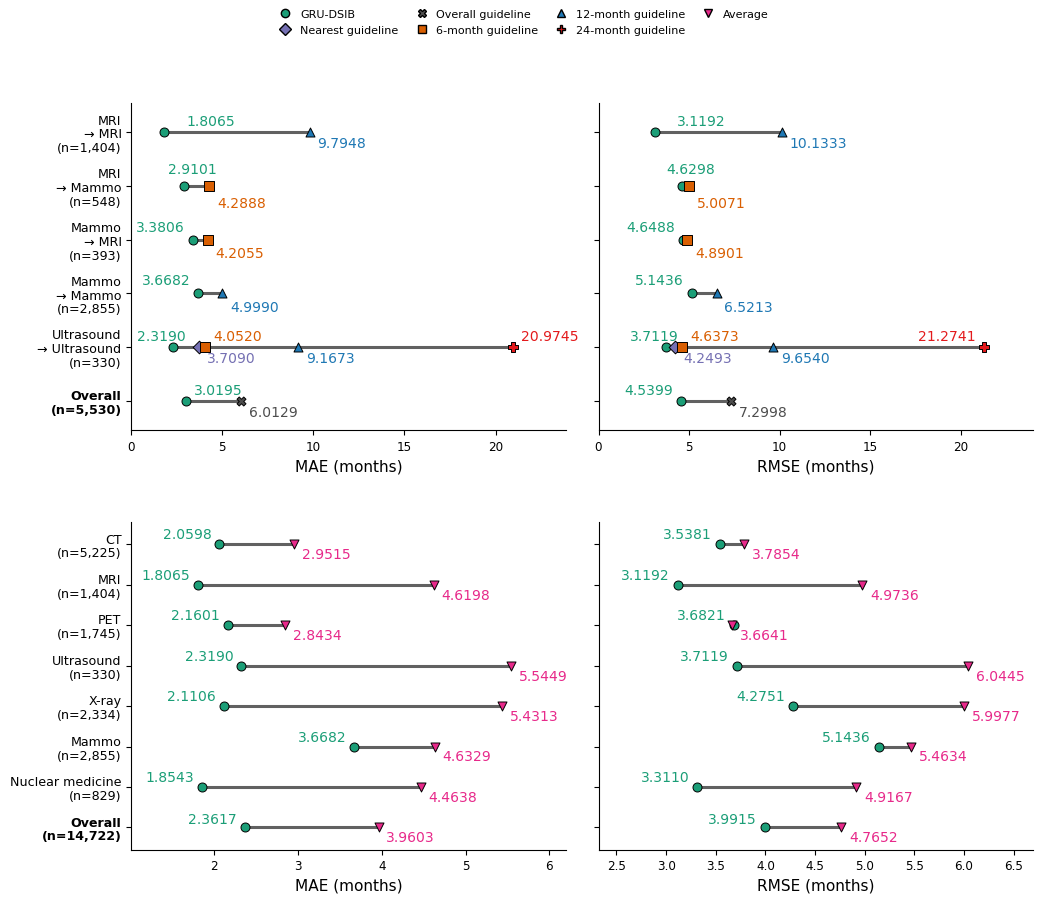

In [5]:
display(tables['guideline_comparison'])
display(tables['average_comparison'])
figure = make_vertical_figure(
    load_guideline_rows(AGGREGATES / 'guideline_comparison.csv'),
    load_average_rows(AGGREGATES / 'average_comparison.csv'),
)
figure.savefig(OUTPUT / 'figure_2_baseline_comparisons.pdf', bbox_inches='tight')
display(figure)
plt.close(figure)


## Figure 3: feature-group contributions

Contributions summarize the saved model comparisons; they are not causal effects.

,model,model_display,feature_group,n_pairs,micro_auc_contribution_mean,macro_auc_contribution_mean,mae_reduction_mean,rmse_reduction_mean
0,LR,Linear,Imaging,4,0.076618,0.112960,0.277095,0.261505
1,XGBOOST,XGBoost,Imaging,4,0.080204,0.113133,0.266442,0.251806
2,MLP,MLP,Imaging,4,0.072215,0.100568,0.247875,0.312490
3,GRU,GRU,Imaging,4,0.105058,0.147227,0.397238,0.495885
4,LSTM,LSTM,Imaging,4,0.101993,0.144038,0.389522,0.507174
5,DECODER_ONLY_TRANSFORMER,Decoder-only Transformer,Imaging,4,0.101898,0.145005,0.374602,0.499402
6,LR,Linear,Mastectomy,4,0.000926,0.001682,0.003260,0.002954
7,XGBOOST,XGBoost,Mastectomy,4,-0.000637,-0.000262,-0.006569,-0.007397
8,MLP,MLP,Mastectomy,4,-0.001240,-0.001246,0.000238,-0.022335
9,GRU,GRU,Mastectomy,4,0.002623,0.003879,0.003337,0.012119


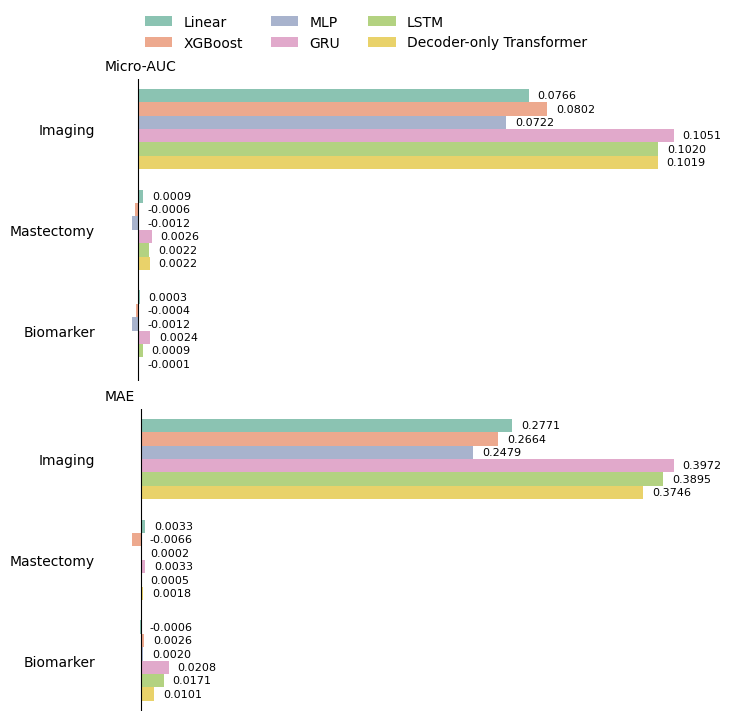

Saved Figure 2 and Figure 3 to generated_figures/.


In [6]:
display(tables['feature_group_contributions'])
figure = plot_feature_group_contribution(tables['feature_group_contributions'])
figure.savefig(OUTPUT / 'figure_3_feature_group_contributions.pdf', bbox_inches='tight')
display(figure)
plt.close(figure)
print('Saved Figure 2 and Figure 3 to generated_figures/.')
